<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Setup. Libraries and settings</h2>

In [1]:
# ===== Setup =====
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns                      # a library on top of matplotlib: nicer defaults with less code
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
import wrds

conn = wrds.Connection()

# Settings (the same as Assignment 8). Change them here only.
SIC        = "36"           # my industry (Transportation Equipment) 37
PEER_SIC   = "49"           # the peer industry for Part 5 (Industrial Machinery and Computer Equipment) 35
FY_START   = "2010-01-01"   # fiscal years that END between FY_START and FY_END
FY_END     = "2023-12-31"
PULL_START = "2008-06-01"   # the EPS change needs last year's EPS and price
RET_START  = "2009-01-01"   # returns must start 12 months before the first fiscal year-end
RET_END    = "2023-12-31"
MIN_PRC    = 5
MAX_CHG    = 1

LABELS = ["Low", "Middle", "High"]

Loading library list...
Done


If `import seaborn` or `import statsmodels` gives an error, run `!pip install seaborn statsmodels` in a new cell once, then restart the kernel.

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 1. Build the table (Assignment 8 code, given)</h2>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px">This is the code you already ran in Assignment 8, put into three cells. <b>Just run it.</b>
The result is <code>events</code>: one row = one company and one fiscal year, with <code>eps_chg</code> and <code>abn_ret</code>.</div>

In [2]:
# ===== Steps 1-2. Link file and Compustat annual data =====
link_all = pd.read_csv("ccm_link.csv", dtype=str)
link_all["gvkey"]     = link_all["gvkey"].str.zfill(6)
link_all["permno"]    = pd.to_numeric(link_all["permno"]).astype(int)
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)

gv = "'" + "','".join(link["gvkey"].unique()) + "'"
fa = conn.raw_sql(f"""
    select gvkey, datadate, fyear, epspx, prcc_f
    from comp.funda
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate"])
fa["epspx"]  = fa["epspx"].astype("float64")
fa["prcc_f"] = fa["prcc_f"].astype("float64")
print("company-years pulled:", len(fa))

company-years pulled: 2930


In [3]:
# ===== Step 3. Merge 1 (link), Merge 2 (last year), EPS change, sample period =====
panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
panel = panel[(panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])]
panel = panel.drop_duplicates(["gvkey", "fyear"]).drop(columns=["linkdt", "linkenddt"])

last = panel[["gvkey", "fyear", "epspx", "prcc_f"]].copy()
last["fyear"] = last["fyear"] + 1
last = last.rename(columns={"epspx": "eps_lag1", "prcc_f": "prc_lag1"})
panel = panel.merge(last, on=["gvkey", "fyear"], how="left")
panel["eps_chg"] = (panel["epspx"] - panel["eps_lag1"]) / panel["prc_lag1"]

events = panel[panel["eps_chg"].notna()]
events = events[(events["datadate"] >= FY_START) & (events["datadate"] <= FY_END)].reset_index(drop=True)
print("company-years in the sample period:", len(events))

company-years in the sample period: 2398


In [4]:
# ===== Steps 4-6. Monthly returns, 12-month abnormal return, rules =====
permnos = ",".join(events["permno"].astype(str).unique())
stock = conn.raw_sql(f"""select permno, date, ret from crsp.msf
                         where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                     date_cols=["date"])
mkt = conn.raw_sql(f"""select date, vwretd from crsp.msi
                       where date between '{RET_START}' and '{RET_END}'""", date_cols=["date"])
stock["permno"] = stock["permno"].astype(int)
stock["ret"]    = stock["ret"].astype("float64")
mkt["vwretd"]   = mkt["vwretd"].astype("float64")
stock["mon"] = stock["date"].dt.year * 12 + stock["date"].dt.month
mkt["mon"]   = mkt["date"].dt.year * 12 + mkt["date"].dt.month
stock = stock.merge(mkt[["mon", "vwretd"]], on="mon", how="left")
stock["ar"] = stock["ret"] - stock["vwretd"]

events["event_id"] = events.index
events["end_mon"]  = events["datadate"].dt.year * 12 + events["datadate"].dt.month
pairs = events[["event_id", "permno", "end_mon"]].merge(stock[["permno", "mon", "ar"]], on="permno", how="inner")
pairs = pairs[(pairs["mon"] <= pairs["end_mon"]) & (pairs["mon"] > pairs["end_mon"] - 12)]
abn = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
abn = abn.rename(columns={"sum": "abn_ret", "count": "months_found"})
events = events.merge(abn, on="event_id", how="left")

events = events[events["months_found"] == 12]                      # Rule 1
events = events[events["prc_lag1"] >= MIN_PRC]                      # Rule 2
events = events[events["eps_chg"].abs() <= MAX_CHG].reset_index(drop=True)   # Rule 3

print("final table:", len(events), "company-years |", events["gvkey"].nunique(), "companies")
events[["ticker", "fyear", "eps_chg", "abn_ret"]].head()

final table: 1791 company-years | 189 companies


,ticker,fyear,eps_chg,abn_ret
0,AMD,2010,0.020661,-0.213715
1,AMD,2011,0.002445,-0.320818
2,AMD,2012,-0.422222,-0.734484
3,AMD,2017,0.056437,-0.180393
4,AMD,2018,0.029183,0.987543


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 2. Three groups and Figure 1 </h2>

**Step 1. Three equal groups.** We rank `eps_chg` first, so that equal values are split evenly and the three groups have the same size.

For each group we compute the average and its **95% confidence interval** (CI):

- standard error = standard deviation ÷ √(number of rows)
- 95% CI = average ± 1.96 × standard error

The CI shows how much the average could move just by luck. A short bar with a long CI tells us little.

In [5]:
# ===== 2a. Groups and the table behind Figure 1 =====
events["group"] = pd.qcut(events["eps_chg"].rank(method="first"), 3, labels=LABELS)

table = events.groupby("group", observed=True)["abn_ret"].agg(n="count", mean="mean", sd="std")
table["se"]   = table["sd"] / np.sqrt(table["n"])
table["ci95"] = 1.96 * table["se"]

(table[["mean", "ci95"]] * 100).round(2).assign(n=table["n"])     # in %, easier to read

,mean,ci95,n
group,,,
Low,-12.79,3.27,597
Middle,1.51,2.32,597
High,13.12,3.13,597


**Step 2. The quick chart.** This is what one line of pandas gives us. It is fine for checking, but not for a client:
no title that says anything, no units, no uncertainty, the labels are rotated, and the colors mean nothing.

<Axes: xlabel='group'>

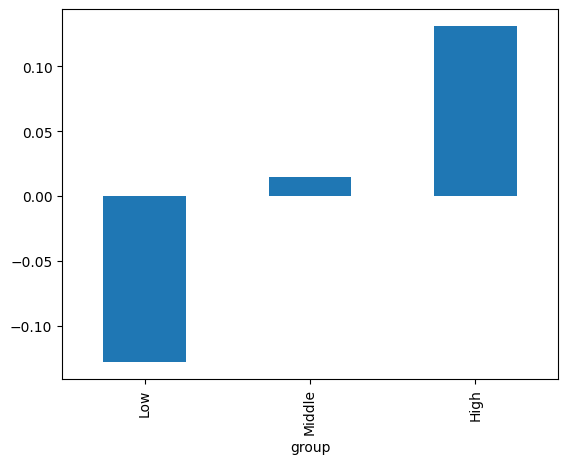

In [6]:
# ===== 2b. The quick (default) chart =====
table["mean"].plot(kind="bar")

**Step 3. The same chart, made for a client.** Six small changes do most of the work:

1. a **theme** (`sns.set_theme`) for a clean background and readable fonts
2. **colors with a meaning**: red = low surprise, grey = middle, blue = high (use the same colors on every slide)
3. **error bars** = the 95% CI
4. the **value and n** written on each bar, so nobody has to read the axis
5. a **title that states the finding** (built from the numbers, so it is always right)
6. no box around the plot (`sns.despine`), and a line at 0

We save the figure as a PNG for the slides.

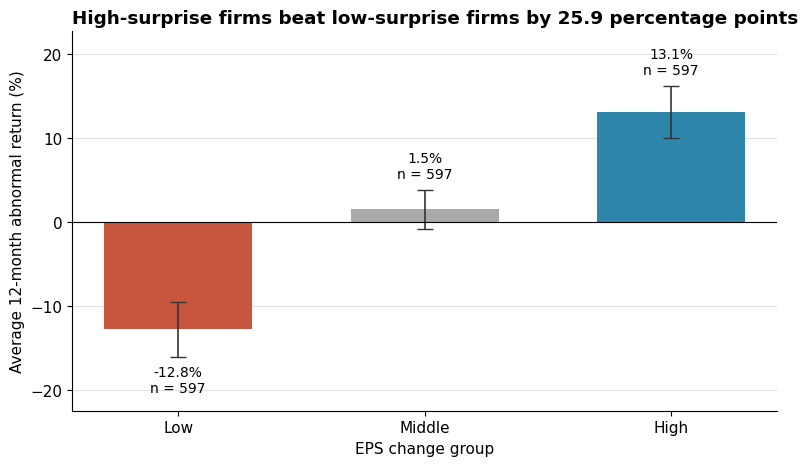

In [7]:
# ===== 2c. Figure 1, made for a client =====

plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
#sns.set_theme(style="whitegrid", font_scale=1.1, rc={"axes.grid.axis": "y"})   # 1. theme (once per notebook), horizontal lines only

COLORS = {"Low": "#C8553D", "Middle": "#A9A9A9", "High": "#2E86AB"}    # 2. colors with a meaning

mean = table["mean"] * 100
ci   = table["ci95"] * 100
spread = mean["High"] - mean["Low"]
word = "beat" if spread > 0 else "trail"
title = f"High-surprise firms {word} low-surprise firms by {abs(spread):.1f} percentage points"   # 5. the finding

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean, yerr=ci, capsize=6, width=0.6,                  # 3. error bars = 95% CI
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # 4. value and n on each bar
    top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
    ax.annotate(f"{mean[g]:.1f}%\nn = {table.loc[g, 'n']}", (i, top),
                xytext=(0, 6 if mean[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)                           # 6. line at 0
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("EPS change group")
ax.set_ylabel("Average 12-month abnormal return (%)")
ax.margins(y=0.2)
#sns.despine(left=True)                                                # 6. no box
plt.tight_layout()
fig.savefig("figure1_groups.png", dpi=200)                            # for your slides
plt.show()

<div style="background:#eaf7ee; border-left:6px solid #2f855a; padding:8px 14px"><b>Read the chart before you test.</b> Do the error bars of Low and High overlap?
If they do not overlap, the difference is very unlikely to be luck. If they overlap a lot, the t-test will probably say "could be luck".</div>

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 3. t-test: is High different from Low?</h2>

The **null hypothesis**: High and Low have the same average, and the gap we see is luck.

- **t-statistic** = the gap ÷ its standard error. Beyond about ±2, the gap is large compared with the noise.
- **p-value** = if there were really no difference, how often would we see a gap this large just by luck?
  Below 0.05 we say "unlikely to be luck".

We use Welch's t-test (`equal_var=False`): it does not assume the two groups have the same spread.

In [8]:
# ===== 3. Welch t-test: High vs Low =====
high = events.loc[events["group"] == "High", "abn_ret"]
low  = events.loc[events["group"] == "Low",  "abn_ret"]

t, p = stats.ttest_ind(high, low, equal_var=False)

gap = (high.mean() - low.mean()) * 100
print(f"High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")

High - Low = 25.92 percentage points | t = 11.21 | p = 0.0000


**Say it to Harry in two sentences** (fill in your numbers):

> *High-surprise firms earned on average X percentage points more than low-surprise firms.
> If there were really no difference, a gap this large would appear by luck about p × 100% of the time, so we treat it as real (p < 0.05) / we cannot rule out luck (p ≥ 0.05).*

A large p-value does **not** prove there is no difference. It means our data cannot tell.

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 4. Outliers and the regression</h2>

The t-test uses only High and Low. A **regression** uses **every row** and asks: when the EPS change goes up, how much does the abnormal return go up on average?

$$\text{abn\_ret} = a + b \times \text{eps\_chg}$$

**Step 1. Outliers.** A few extreme values can pull the line. Rules 2 and 3 already removed the worst EPS changes.
For the return, a common fix is to **winsorize**: values below the 1st percentile are set to the 1st percentile, values above the 99th to the 99th.
No row is deleted, only the most extreme values are pulled in. We run the regression both ways and compare.

In [9]:
# ===== 4a. Look at the extremes, then winsorize the return at 1% and 99% =====
print(events[["eps_chg", "abn_ret"]].describe().round(3))

lo, hi = events["abn_ret"].quantile([0.01, 0.99])
events["abn_ret_w"] = events["abn_ret"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge
print(f"\nrows changed by winsorizing: {(events['abn_ret'] != events['abn_ret_w']).sum()} of {len(events)}")

        eps_chg   abn_ret
count  1791.000  1791.000
mean      0.005     0.006
std       0.108     0.381
min      -0.747    -1.981
25%      -0.021    -0.198
50%       0.003     0.008
75%       0.026     0.218
max       0.871     2.928

rows changed by winsorizing: 36 of 1791


**Step 2. The regression.** `smf.ols("y ~ x", data=...)` reads like the formula. The table below has everything we need:

| Number | Where | What it means |
|---|---|---|
| **b** (slope) | `coef` of `eps_chg` | the change in `abn_ret` when `eps_chg` goes up by 1 |
| **p-value of b** | `P>|t|` of `eps_chg` | could the true slope be 0? |
| **R²** | `R-squared` | the share of the ups and downs in `abn_ret` that `eps_chg` explains (0 to 1) |

In [10]:
# ===== 4b. Regression: original and winsorized =====
model   = smf.ols("abn_ret ~ eps_chg", data=events).fit()
model_w = smf.ols("abn_ret_w ~ eps_chg", data=events).fit()

print(model.summary())      # full results table, original
print(model_w.summary())    # full results table, winsorized

results = pd.DataFrame({
    "b (slope)":    [model.params["eps_chg"],  model_w.params["eps_chg"]],
    "p-value of b": [model.pvalues["eps_chg"], model_w.pvalues["eps_chg"]],
    "R-squared":    [model.rsquared,           model_w.rsquared],
    "n":            [int(model.nobs),          int(model_w.nobs)],
}, index=["original", "winsorized 1%/99%"]).round(4)
results

                            OLS Regression Results                            
Dep. Variable:                abn_ret   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.064
Method:                 Least Squares   F-statistic:                     122.8
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.19e-27
Time:                        20:30:30   Log-Likelihood:                -753.67
No. Observations:                1791   AIC:                             1511.
Df Residuals:                    1789   BIC:                             1522.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0013      0.009      0.149      0.8

,b (slope),p-value of b,R-squared,n
original,0.8921,0.0,0.0642,1791
winsorized 1%/99%,0.8530,0.0,0.0676,1791


In [11]:
events.info

<bound method DataFrame.info of        gvkey   datadate  fyear  epspx  prcc_f  permno ticker  eps_lag1  \
0     001161 2010-12-31   2010   0.66    8.18   61241    AMD      0.46   
1     001161 2011-12-31   2011   0.68    5.40   61241    AMD      0.66   
2     001161 2012-12-31   2012  -1.60    2.40   61241    AMD      0.68   
3     001161 2017-12-31   2017   0.04   10.28   61241    AMD     -0.60   
4     001161 2018-12-31   2018   0.34   18.46   61241    AMD      0.04   
...      ...        ...    ...    ...     ...     ...    ...       ...   
1786  270705 2017-12-31   2017   0.16   10.42   91163   HIMX      0.30   
1787  270705 2018-12-31   2018   0.05    3.43   91163   HIMX      0.16   
1788  270705 2021-12-31   2021   2.50   15.99   91163   HIMX      0.27   
1789  270705 2022-12-31   2022   1.36    6.21   91163   HIMX      2.50   
1790  270705 2023-12-31   2023   0.29    6.07   91163   HIMX      1.36   

      prc_lag1   eps_chg  event_id  end_mon   abn_ret  months_found   group  \


In [12]:
events["fyear"] = events["fyear"].astype(int)           # nullable Int64 -> plain int
events["loss"]  = (events["epspx"] < 0).astype(int)     # 1 = loss firm
lo, hi = events["abn_ret"].quantile([0.01, 0.99])
events["abn_ret_w"] = events["abn_ret"].clip(lo, hi)

cl = dict(cov_type="cluster", cov_kwds={"groups": events["gvkey"]})

m1 = smf.ols("abn_ret_w ~ eps_chg", data=events).fit(**cl)
m2 = smf.ols("abn_ret_w ~ eps_chg + C(fyear)", data=events).fit(**cl)
m3 = smf.ols("abn_ret_w ~ eps_chg * loss + C(fyear)", data=events).fit(**cl)
from statsmodels.iolib.summary2 import summary_col

summary_col([m1, m2, m3], stars=True,
            model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
            regressor_order=["eps_chg", "loss", "eps_chg:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) base,(2) year FE,(3) year FE + loss
eps_chg,0.8530***,0.8355***,1.0187***
,(0.0997),(0.0981),(0.1401)
loss,,,-0.1718***
,,,(0.0216)
eps_chg:loss,,,-0.6823***
,,,(0.1945)
R-squared,0.0676,0.1044,0.1500
R-squared Adj.,0.0671,0.0969,0.1418
R2,0.068,0.104,0.150
n,1791,1791,1791


**Read b in plain words.** An EPS change of 1 means EPS moved by 100% of the share price, which never happens. A change of **0.01** (1% of the price) is more natural:

> *When the EPS change is 0.01 higher, the 12-month abnormal return is on average b × 0.01 × 100 percentage points higher.*

**R² is small? That is normal.** Returns move for many reasons besides earnings. The surprise can matter on average (a clear slope)
and still explain little of any single company's return. This is a good **limitation** for your report.

If the original and the winsorized results tell the same story, say so: your result does not depend on a few extreme rows.

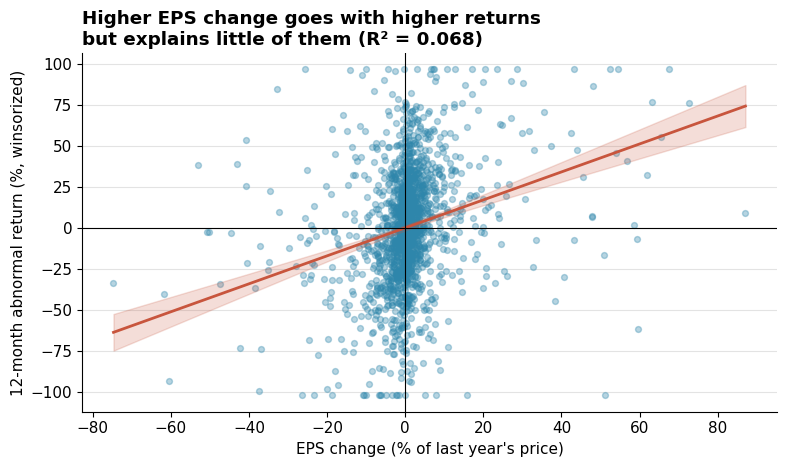

In [13]:
# ===== 4c. Figure 2: every company-year and the regression line =====
b  = model_w.params["eps_chg"]
r2 = model_w.rsquared
title = (f"Higher EPS change goes with {'higher' if b > 0 else 'lower'} returns\n"
         f"but explains little of them (R² = {r2:.3f})")

# the regression line and its 95% band, from the fitted model
grid = pd.DataFrame({"eps_chg": np.linspace(events["eps_chg"].min(), events["eps_chg"].max(), 100)})
pred = model_w.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(events["eps_chg"] * 100, events["abn_ret_w"] * 100,
           s=18, alpha=0.35, color="#2E86AB")                                   # every company-year
ax.fill_between(grid["eps_chg"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                color="#C8553D", alpha=0.2)                                     # 95% band
ax.plot(grid["eps_chg"] * 100, pred["mean"] * 100, color="#C8553D", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("EPS change (% of last year's price)")
ax.set_ylabel("12-month abnormal return (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)                                  # no box
plt.tight_layout()
fig.savefig("figure2_regression.png", dpi=200)
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 5. The peer industry, with a class (OOP)</h2>

Project 3 asks for a **peer comparison**. We need Parts 1 to 4 again for another industry.

**Option 1: copy every cell and change `SIC`.** It works, but you now have two copies of everything.
Fix a bug in one copy and forget the other, and your two industries are no longer built the same way.

**Option 2: write the steps once, as a class, and use it twice.**

| Word | Meaning | Here |
|---|---|---|
| **class** | a recipe | `Industry`: how to build and analyze one industry |
| **object** | one thing made from the recipe | `mine = Industry("37", ...)`, `peer = Industry("35", ...)` |
| **attribute** | data stored inside the object | `self.sic`, `self.name`, `self.events` |
| **method** | a function that belongs to the class | `.build()`, `.ttest()`, `.regression()` |
| `self` | "this object" | inside the recipe, `self.sic` is *this* industry's SIC |
| `__init__` | runs once when the object is created | stores the SIC and the name |

Nothing inside the methods is new: it is the code of Parts 1 to 4, with `SIC` replaced by `self.sic` and `events` by `self.events`.

In [14]:
events.info

<bound method DataFrame.info of        gvkey   datadate  fyear  epspx  prcc_f  permno ticker  eps_lag1  \
0     001161 2010-12-31   2010   0.66    8.18   61241    AMD      0.46   
1     001161 2011-12-31   2011   0.68    5.40   61241    AMD      0.66   
2     001161 2012-12-31   2012  -1.60    2.40   61241    AMD      0.68   
3     001161 2017-12-31   2017   0.04   10.28   61241    AMD     -0.60   
4     001161 2018-12-31   2018   0.34   18.46   61241    AMD      0.04   
...      ...        ...    ...    ...     ...     ...    ...       ...   
1786  270705 2017-12-31   2017   0.16   10.42   91163   HIMX      0.30   
1787  270705 2018-12-31   2018   0.05    3.43   91163   HIMX      0.16   
1788  270705 2021-12-31   2021   2.50   15.99   91163   HIMX      0.27   
1789  270705 2022-12-31   2022   1.36    6.21   91163   HIMX      2.50   
1790  270705 2023-12-31   2023   0.29    6.07   91163   HIMX      1.36   

      prc_lag1   eps_chg  event_id  end_mon   abn_ret  months_found   group  \


In [15]:
# ===== 5a. The class =====
class Industry:
    """One industry: build its table, then group, test, and regress."""

    def __init__(self, sic, name):
        self.sic = sic              # attributes: data that belongs to this object
        self.name = name
        self.events = None          # filled by build()

    # ---------- Part 1: build the table (the same code as Part 1) ----------
    def build(self):
        link = link_all[link_all["sic2"] == self.sic]
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"
        fa = conn.raw_sql(f"""
            select gvkey, datadate, fyear, epspx, prcc_f from comp.funda
            where gvkey in ({gv}) and datadate between '{PULL_START}' and '{FY_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate"])
        fa[["epspx", "prcc_f"]] = fa[["epspx", "prcc_f"]].astype("float64")

        panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
        panel = panel[(panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])]
        panel = panel.drop_duplicates(["gvkey", "fyear"]).drop(columns=["linkdt", "linkenddt"])
        last = panel[["gvkey", "fyear", "epspx", "prcc_f"]].copy()
        last["fyear"] = last["fyear"] + 1
        last = last.rename(columns={"epspx": "eps_lag1", "prcc_f": "prc_lag1"})
        panel = panel.merge(last, on=["gvkey", "fyear"], how="left")
        panel["eps_chg"] = (panel["epspx"] - panel["eps_lag1"]) / panel["prc_lag1"]
        events = panel[panel["eps_chg"].notna()]
        events = events[(events["datadate"] >= FY_START) & (events["datadate"] <= FY_END)].reset_index(drop=True)

        permnos = ",".join(events["permno"].astype(str).unique())
        stock = conn.raw_sql(f"""select permno, date, ret from crsp.msf
                                 where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                             date_cols=["date"])
        stock["permno"] = stock["permno"].astype(int)
        stock["ret"] = stock["ret"].astype("float64")
        stock["mon"] = stock["date"].dt.year * 12 + stock["date"].dt.month
        stock = stock.merge(mkt[["mon", "vwretd"]], on="mon", how="left")      # mkt from Part 1: the same for every industry
        stock["ar"] = stock["ret"] - stock["vwretd"]

        events["event_id"] = events.index
        events["end_mon"] = events["datadate"].dt.year * 12 + events["datadate"].dt.month
        pairs = events[["event_id", "permno", "end_mon"]].merge(stock[["permno", "mon", "ar"]], on="permno", how="inner")
        pairs = pairs[(pairs["mon"] <= pairs["end_mon"]) & (pairs["mon"] > pairs["end_mon"] - 12)]
        abn = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
        abn = abn.rename(columns={"sum": "abn_ret", "count": "months_found"})
        events = events.merge(abn, on="event_id", how="left")
        events = events[events["months_found"] == 12]
        events = events[events["prc_lag1"] >= MIN_PRC]
        events = events[events["eps_chg"].abs() <= MAX_CHG].reset_index(drop=True)

        # Part 2 groups and Part 4 winsorizing, so every method below can use them
        events["group"] = pd.qcut(events["eps_chg"].rank(method="first"), 3, labels=LABELS)
        lo, hi = events["abn_ret"].quantile([0.01, 0.99])
        events["abn_ret_w"] = events["abn_ret"].clip(lo, hi)

        self.events = events
        print(f"{self.name} (SIC {self.sic}): {len(events)} company-years, {events['gvkey'].nunique()} companies")
        return self                 # returning self lets us write Industry(...).build() in one line

    # ---------- Part 2: the group table ----------
    def group_table(self):
        t = self.events.groupby("group", observed=True)["abn_ret"].agg(n="count", mean="mean", sd="std")
        t["ci95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
        return t

    # ---------- Part 3: the t-test ----------
    def ttest(self):
        high = self.events.loc[self.events["group"] == "High", "abn_ret"]
        low  = self.events.loc[self.events["group"] == "Low",  "abn_ret"]
        t, p = stats.ttest_ind(high, low, equal_var=False)
        return {"High - Low (pp)": (high.mean() - low.mean()) * 100, "t": t, "p (t-test)": p}

    # ---------- Part 4: the regression (winsorized) ----------
    def regression(self):
        m = smf.ols("abn_ret_w ~ eps_chg", data=self.events).fit()
        return {"b": m.params["eps_chg"], "p (b)": m.pvalues["eps_chg"], "R2": m.rsquared}

    # ---------- everything in one row ----------
    def summary(self):
        row = {"industry": self.name, "SIC": self.sic, "n": len(self.events),
               "companies": self.events["gvkey"].nunique()}
        row.update(self.ttest())
        row.update(self.regression())
        return row

Now the class does all the work. Two lines build both industries:

In [16]:
# ===== 5b. Two objects from one recipe =====
mine = Industry(SIC, "Electronic and Other Electrical Equipment and Components").build()
peer = Industry(PEER_SIC, "Electric, Gas, and Sanitary Services").build()

Electronic and Other Electrical Equipment and Components (SIC 36): 1791 company-years, 189 companies
Electric, Gas, and Sanitary Services (SIC 49): 1356 company-years, 122 companies


In [17]:
# ===== 5c. The comparison table: one row per industry =====
compare = pd.DataFrame([mine.summary(), peer.summary()]).set_index("industry")
compare.round(4)

,SIC,n,companies,High - Low (pp),t,p (t-test),b,p (b),R2
industry,,,,,,,,,
Electronic and Other Electrical Equipment and Components,36,1791,189,25.9156,11.2145,0.0,0.8530,0.0,0.0676
"Electric, Gas, and Sanitary Services",49,1356,122,13.5085,6.9944,0.0,0.6088,0.0,0.0422


**Figure 3. The two industries side by side.** The same chart as Figure 1, with one color per **industry** this time
(keep these colors on every slide). It is a plain function, because it uses two objects at once.

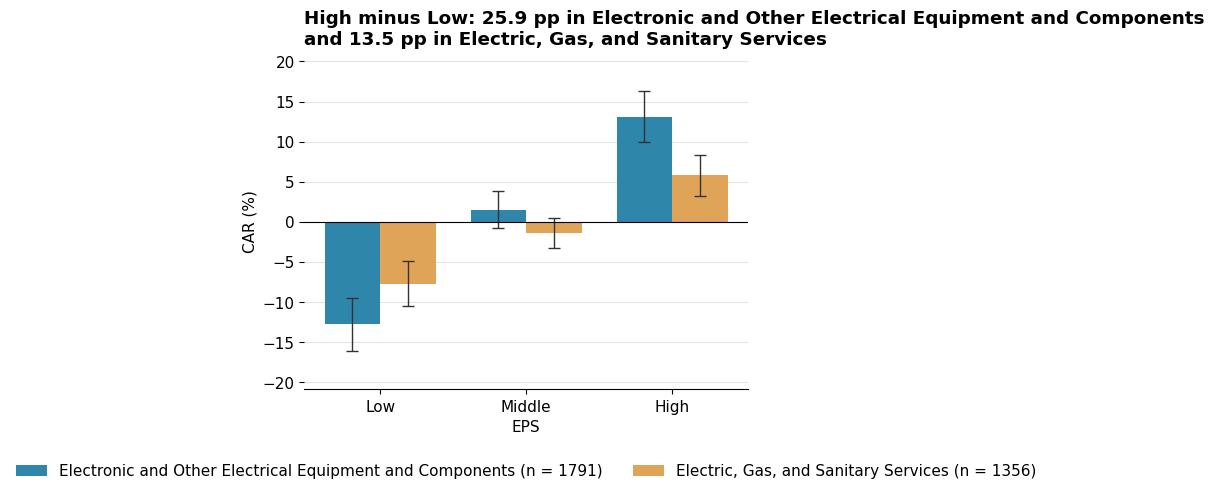

In [18]:
# ===== 5d. Figure 3: my industry vs the peer industry =====
def plot_compare(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        t = ind.group_table()
        ax.bar(x + (j - 0.5) * width, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=4,
               color=colors[j], label=f"{ind.name} (n = {len(ind.events)})",
               error_kw={"elinewidth": 1, "ecolor": "#333333"})
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, LABELS)
    gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
    ax.set_title(f"High minus Low: {gaps[0]:.1f} pp in {industries[0].name}\n"
                 f"and {gaps[1]:.1f} pp in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("EPS")
    ax.set_ylabel("CAR (%)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))   # legend under the chart
    ax.margins(y=0.15)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_compare([mine, peer], colors=["#2E86AB", "#E0A458"], file_name="figure3_peer.png")

<div style="background:#eaf7ee; border-left:6px solid #2f855a; padding:8px 14px"><b>Why OOP helps here.</b> Adding a third industry is one line: <code>third = Industry("28", "Chemicals").build()</code>.
Every industry is built by the same code, so differences in the table come from the data, not from a copy that drifted.</div>

<div style="background:#e8f1fb; border-left:6px solid #2b6cb0; padding:8px 14px"><b>For your project.</b> You do <b>not</b> have to use a class. Two clean notebooks (yours and the peer) built the same way are fine.
If you want to try it: put your Project 2 steps inside <code>build()</code>, change <code>eps_chg</code> to <code>sue</code> and <code>abn_ret</code> to <code>car</code>, and keep everything else.</div>

<h2 style="background:#7b1e1e; color:white; padding:8px 14px; border-radius:4px">Part 6. Project 3 checklist</h2>

**Analysis**

- [ ] Your Project 2 table, revised with my comments (rules 1 to 6, the sample construction table).
- [ ] Outliers: say what you did (the rules, and winsorizing CAR at 1%/99% or not) and show that the result does not depend on it.
- [ ] **Figure 1**: average CAR by SUE group with 95% CI.
- [ ] **t-test** High vs Low, in two plain sentences.
- [ ] **Regression** CAR = a + b × SUE: b in plain words (for SUE + 0.01), its p-value, R², and n.
- [ ] **Peer industry**: the same steps, one comparison table, and Figure 3.

**Figures (every figure)**

- [ ] The title states the **finding**, not the topic.
- [ ] Axis labels with **units** (%).
- [ ] The **same color for the same thing** on every slide.
- [ ] A line at 0.

**Interpretation**

- Results do **not** need to be significant. Explain what you find and what it means for the client.
- Name at least one **limitation** (small R², few companies, one period, CAR measures only 3 days).

**Before you submit:** Kernel > Restart & Run All, and check that every number in the report matches the notebook.

In [19]:
conn.close()